# Bloc C : adaptation QLoRA du tuteur, étape par étape

- **Le tuteur** reçoit une fiche de cours, une question et la réponse d'un élève. Il répond par un verdict (`PARFAIT`, `PARTIEL`, `INCORRECT` ou `HORS_PERIMETRE`), puis par un feedback.
- **Ce notebook** montre chaque étape de la partie QLoRA, de l'installation aux résultats : ce que le modèle apprend, pourquoi on s'arrête à ce moment de l'entraînement, pourquoi ces réglages.
- **Il se lit avec ses sorties** : tout est déjà affiché. Les chiffres sont lus dans des fichiers ou calculés, jamais recopiés à la main.
- **Il s'exécute sur Google Colab avec un GPU Nvidia** (Exécution > Tout exécuter). Une A100 est conseillée ; une L4 ou une T4 marchent aussi, avec des lots plus petits et plus lentement. La durée dépend de ce qui est déjà fait : les étapes dont les fichiers existent sont sautées. Sur A100, l'entraînement complet a pris 70 min, puis les évaluations sur `val` et `test` environ une heure de plus. Ce n'est pas le notebook final du projet : les sections sont faites pour être reprises telles quelles dans un notebook commun.

### En deux mots

```
fiche + question + réponse de l'élève  →  Qwen2.5-3B (gelé) + adaptateur  →  [VERDICT: X] + feedback

installation → données → modèle 4 bits + adaptateur → entraînement → mesure sur val → meilleur adaptateur gardé → mesure finale sur test
```

- **modèle gelé** : les poids de Qwen ne changent jamais pendant l'entraînement.
- **adaptateur (LoRA)** : de petites matrices ajoutées à côté des couches de Qwen. Elles sont les seules à être entraînées. C'est ce petit dossier que l'on sauvegarde.
- **QLoRA** : LoRA, avec en plus le modèle gelé stocké en 4 bits pour qu'il tienne en mémoire.
- **token** : un morceau de mot, l'unité que le modèle lit et écrit.
- **loss** : erreur moyenne du modèle, token par token, sur la réponse attendue du tuteur. Plus elle est basse, plus il écrit comme le dataset.
- **epoch** : un passage complet sur les exemples d'entraînement.
- **pas** : une correction de l'adaptateur.
- **lot** : les conversations passées ensemble au modèle.
- **accumulation** : additionner plusieurs petits lots avant de corriger. Même effet qu'un grand lot, avec moins de mémoire.
- **lot effectif** : lot x accumulation, c'est-à-dire le nombre de conversations derrière chaque pas.
- **learning rate** : la taille de chaque correction de l'adaptateur.
- **dropout** : une partie des valeurs est mise à zéro au hasard pendant l'entraînement, pour éviter d'apprendre par cœur.
- **train / val / test** : `train` sert à apprendre ; `val` (jamais appris) sert à suivre la loss et à choisir le meilleur adaptateur ; `test` (jamais appris, jamais utilisé pour choisir) sert uniquement à la mesure finale. Les trois splits sont découpés par question entière : une question n'apparaît que dans un seul split.
- **HORS_PERIMETRE** : la réponse de l'élève sort du sujet de la fiche. Le tuteur doit refuser de la noter et recadrer.

## 0. Mise en place

- **GPU.** Le chargement en 4 bits (`bitsandbytes`) exige un GPU Nvidia. La cellule échoue tout de suite s'il n'y en a pas (Exécution > Modifier le type d'exécution). Elle choisit aussi la découpe du lot selon la mémoire du GPU.
- **Drive.** Une fenêtre Google va s'ouvrir pour demander l'autorisation d'accéder au Drive : il faut l'accepter. Adaptateurs et évaluations sont écrits sur Drive, car une session Colab coupée perd tout ce qui n'y est pas.
- **Code.** On clone le dépôt sur la branche `BRANCH` (à remplacer par `main` après la fusion). Si le dossier existe déjà, on ne le reclone pas.
- **Bibliothèques.** Leurs versions sont figées dans `requirements-qlora.txt`. PyTorch est déjà installé sur Colab : on ne le réinstalle pas. Si Colab demande de redémarrer la session après `pip`, le faire et relancer à partir de la cellule Drive.

In [2]:
!nvidia-smi
import torch

assert torch.cuda.is_available(), "Aucun GPU : Exécution > Modifier le type d'exécution > GPU"
gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3  # sert à choisir la découpe du lot juste en dessous
print(f"GPU : {torch.cuda.get_device_name(0)}, {gpu_gb:.0f} Go de mémoire")
BATCH, ACCUM = (8, 1) if gpu_gb > 60 else (4, 2)  # même lot effectif de 8 ; 8 conversations en parallèle demandent beaucoup de mémoire
print(f"lot de cette session, utilisé seulement si l'entraînement est lancé ici : {BATCH} x {ACCUM} = {BATCH * ACCUM} (le run déjà fait : voir config.json)")

Mon Oct 19 20:46:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   33C    P0             52W /  400W |       6MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
import os
from google.colab import drive

drive.mount("/content/drive")
RUN_NAME = "v1.1"  # v1.1 : premier run sur le split train/val/test par question ; nom de ce run ; en choisir un autre pour ne pas réutiliser le dossier d'un run précédent
SAVE_DIR = "/content/drive/MyDrive/brainmaxing/adapters"
EVAL_DIR = "/content/drive/MyDrive/brainmaxing/eval"
RUN_DIR = f"{SAVE_DIR}/{RUN_NAME}"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(EVAL_DIR, exist_ok=True)
print("adaptateur et résultats du run :", RUN_DIR)

Mounted at /content/drive
adaptateur et résultats du run : /content/drive/MyDrive/brainmaxing/adapters/v1.1


In [4]:
BRANCH = "bloc-c-entrainement"  # "main" après la fusion de la branche
REPO_URL = "https://github.com/EmineOA/NLP-Transformers.git"

%cd /content
![ -d NLP-Transformers ] || git clone --branch {BRANCH} {REPO_URL}
%cd /content/NLP-Transformers
!git pull
!pip install -q -r requirements-qlora.txt

import csv, json, math, sys
from importlib.metadata import version
from pathlib import Path
from IPython.display import Image, Markdown, display

sys.path.insert(0, os.getcwd())  # pour importer src.training
RESULTS = Path("experiments/results")  # les essais précédents (v0.2, v0.3) sont versionnés dans le dépôt
for package in ["torch", "transformers", "peft", "bitsandbytes", "accelerate", "matplotlib"]:
    print(f"{package:<14}{version(package)}")
!git rev-parse --short HEAD

/content
Cloning into 'NLP-Transformers'...
remote: Enumerating objects: 795, done.
remote: Counting objects: 100% (400/400), done.
remote: Compressing objects: 100% (209/209), done.
remote: Total 795 (delta 215), reused 311 (delta 178), pack-reused 395 (from 1)
Receiving objects: 100% (795/795), 2.14 MiB | 19.54 MiB/s, done.
Resolving deltas: 100% (340/340), done.
/content/NLP-Transformers
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 62.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 153.8 MB/s eta 0:00:00a 0:00:01
torch         2.11.0+cu130
transformers  5.20.1
peft          0.21.2
bitsandbytes  0.50.2
accelerate    1.15.0
matplotlib    3.11.2
b44855e


### Raccourci : utiliser directement l'adaptateur entraîné

L'adaptateur publié en accès public sur Hugging Face est celui du run v1.0 : [MonsieurNikko/brainmaxing-qlora-v1.0](https://huggingface.co/MonsieurNikko/brainmaxing-qlora-v1.0). Il a été entraîné sur l'ancien split (885 / 118), avant le découpage par question. L'adaptateur du run v1.1, mesuré dans ce notebook, est dans `adapters/v1.1/best` sur le Drive ; il n'est pas encore publié.

- **Pour qui** : tester le tuteur entraîné sans le réentraîner (équipe, correcteur).
- **Ce que fait la cellule suivante** : elle télécharge l'adaptateur dans `adapters/v1.0/best`, le dossier qu'attend `generate_response(..., model_version="lora")`. Le modèle de base Qwen se télécharge tout seul au premier appel.
- **Prérequis** : la cellule « Mise en place » (dépôt cloné). Générer demande bien moins de mémoire qu'entraîner : une A100 n'est pas nécessaire (pas encore essayé sur un GPU plus petit).
- **La cellule d'après** fait juger une réponse d'élève par le tuteur entraîné, avec la même fonction que l'application.
- La suite du notebook explique comment cet adaptateur a été obtenu.


In [5]:
from huggingface_hub import snapshot_download

# même dossier que LORA_ADAPTER_DIR dans src/agents/inference.py
snapshot_download("MonsieurNikko/brainmaxing-qlora-v1.0", local_dir="/content/NLP-Transformers/adapters/v1.0/best")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

'/content/NLP-Transformers/adapters/v1.0/best'

In [6]:
%cd /content/NLP-Transformers
import sys
sys.path.insert(0, "/content/NLP-Transformers")  # pour que Python trouve le dossier src/ du dépôt

from src.agents.inference import generate_response

# Préfixe identique au dataset d'entraînement (point encore à trancher avec Emine)
message = {"role": "user", "content": "RÉPONSE ACTUELLE À ÉVALUER :\nJe change, car le présentateur sait où est la voiture et ne l'ouvre jamais."}
result = generate_response([message], "monty-hall", "monty-hall_q1", model_version="lora")
print(result["verdict"], "|", result["feedback"])

/content/NLP-Transformers


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

PARFAIT | Tu utilises le savoir du présentateur pour expliquer ton changement. Ton choix repose sur une raison liée aux chances.


## 1. Ce que le modèle apprend

### 1.1 Les données

Une conversation contient trois messages : le prompt système (le rôle du tuteur, la fiche de cours, la grille et les règles), le message de l'élève, puis la réponse attendue du tuteur. Le modèle apprend à écrire cette réponse.

Il apprend trois choses : le **format** (le verdict d'abord), le **jugement** (comparer la réponse de l'élève à la fiche) et le **refus** (`HORS_PERIMETRE` quand la réponse sort du sujet). Il n'apprend pas le contenu des fiches : elles sont dans le prompt.

Les conversations sont réparties en trois splits, découpés par question entière (11 questions pour `train`, 3 pour `val`, 3 pour `test`) : `train` (le modèle apprend dessus), `val` (on suit la loss et on choisit l'adaptateur retenu) et `test` (mesure finale seulement). Le modèle est donc toujours mesuré sur des questions qu'il n'a jamais vues. Les deux cellules suivantes montrent un exemple, puis comptent les verdicts, les longueurs et ce qui compte vraiment dans la loss.

In [7]:
from transformers import AutoTokenizer
from src.training.dataset import load_split

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")  # le tokenizer seul, pas le modèle
system, student, tutor = load_split("train")[0]  # fiche + règles, réponse de l'élève, réponse du tuteur
print("--- prompt système (début) ---")
print(system["content"].split("COURS ACCESSIBLE")[0].strip())
print("[… fiche, grille et règles masquées …]")
print("\n--- message de l'élève ---")
print(student["content"])
print("\n--- réponse du tuteur (ce que le modèle doit produire) ---")
print(tutor["content"])

--- prompt système (début) ---
Tu es Brainmaxxing, un tuteur qui évalue la réponse d'un étudiant.
Applique la grille propre à la QUESTION ACTUELLE ; n'impose pas ta propre opinion.

CONCEPT : L'identité à travers le changement (identité personnelle)
MATIÈRE : philosophie
QUESTION ACTUELLE : Ce bateau, dont toutes les planches ont été remplacées, est-il encore le bateau de Thésée ? Réponds oui ou non, puis surtout : qu'est-ce qui, selon toi, fait qu'un objet reste « le même » ? Essaie de formuler ta règle en une phrase.
[… fiche, grille et règles masquées …]

--- message de l'élève ---
RÉPONSE ACTUELLE À ÉVALUER :
Non. Pour moi un objet c'est sa matière, et là il ne reste plus une seule planche d'origine, donc ce qui est au port c'est une réplique.

--- réponse du tuteur (ce que le modèle doit produire) ---
[VERDICT: PARFAIT]
Net et sans détour. Tu poses ton critère, la matière, et ton « non » en sort tout seul, avec le mot « réplique » pour dire ce que devient le bateau du port.


In [8]:
import collections
from src.training.dataset import DATA_DIR, IGNORE_INDEX, SPLITS, token_lengths, tokenize_example

with open(DATA_DIR / "dataset_source.csv", encoding="utf-8-sig", newline="") as file:
    source_rows = list(csv.DictReader(file, delimiter=";"))
verdicts = ("PARFAIT", "PARTIEL", "INCORRECT", "HORS_PERIMETRE")
for split in SPLITS:  # train, val, test
    counts = collections.Counter(r["label"] for r in source_rows if r["split"] == split)
    print(f"{split:5} {sum(counts.values())} exemples : " + ", ".join(f"{v} {counts[v]}" for v in verdicts))

lengths = token_lengths([c for split in SPLITS for c in load_split(split)], tokenizer)
print(f"\nlongueur d'une conversation : de {min(lengths)} à {max(lengths)} tokens (moyenne {sum(lengths) / len(lengths):.0f})")
encoded = tokenize_example(load_split("train")[0], tokenizer)
learned = sum(label != IGNORE_INDEX for label in encoded["labels"])
print(f"premier exemple : {learned} tokens appris (réponse du tuteur), {len(encoded['labels']) - learned} masqués (le prompt)")
print("Seule la réponse du tuteur compte dans la loss : le prompt est lu, pas appris.")

train 649 exemples : PARFAIT 176, PARTIEL 176, INCORRECT 176, HORS_PERIMETRE 121
val   177 exemples : PARFAIT 48, PARTIEL 48, INCORRECT 48, HORS_PERIMETRE 33
test  177 exemples : PARFAIT 48, PARTIEL 48, INCORRECT 48, HORS_PERIMETRE 33

longueur d'une conversation : de 1229 à 3638 tokens (moyenne 2358)
premier exemple : 56 tokens appris (réponse du tuteur), 1589 masqués (le prompt)
Seule la réponse du tuteur compte dans la loss : le prompt est lu, pas appris.


### 1.2 Le modèle et l'adaptateur

- **4 bits.** Chaque poids de Qwen est stocké sur 4 bits au lieu de 16. Le modèle prend beaucoup moins de place sur le GPU, au prix d'un peu de précision. La cellule suivante affiche la mémoire réellement utilisée (les embeddings et la dernière couche restent en 16 bits).
- **LoRA.** À côté de chaque grande matrice gelée `W`, on ajoute deux petites matrices `A` et `B`. La sortie devient `W·x + (alpha / r) · B · A · x`. Seules `A` et `B` changent : `r` (le rang) est leur taille, `alpha / r` règle la force de la correction.
- **Où.** Sur les 7 couches linéaires de chaque bloc du modèle : 4 dans l'attention (q, k, v, o) et 3 dans le MLP (gate, up, down).

La cellule suivante charge le modèle, ajoute l'adaptateur, puis affiche la mémoire utilisée et la part des paramètres qui sont entraînés. Elle libère ensuite le GPU : l'entraînement (§1.3) tourne dans un autre processus qui recharge le modèle lui-même. La première fois, le téléchargement de Qwen prend quelques minutes.

In [9]:
import gc
from src.training.model import add_lora, load_model_4bit

model, _ = load_model_4bit()
gb_4bit = torch.cuda.memory_allocated() / 1024**3  # réutilisé au §3
print(f"modèle en 4 bits : {gb_4bit:.1f} Go sur le GPU")
model = add_lora(model)
n_trainable, n_total = model.get_nb_trainable_parameters()  # compte correctement les poids 4 bits
print(f"avec l'adaptateur : {torch.cuda.memory_allocated() / 1024**3:.1f} Go")
print(f"paramètres entraînés : {n_trainable:,} sur {n_total:,} ({100 * n_trainable / n_total:.2f} %)".replace(",", " "))
del model
gc.collect()
torch.cuda.empty_cache()  # l'entraînement a besoin de tout le GPU
print(f"après libération : {torch.cuda.memory_allocated() / 1024**3:.2f} Go")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

modèle en 4 bits : 4.0 Go sur le GPU
avec l'adaptateur : 4.7 Go
paramètres entraînés : 29 933 568 sur 3 115 872 256 (0.96 %)
après libération : 2.04 Go


### 1.3 L'entraînement

Une seule commande, `src/training/run_training.py`, fait tout. Avec les options ci-dessous :

- un **pas** = un lot effectif de 8 conversations (`--batch-size` x `--accumulation-steps`, choisis selon la mémoire du GPU dans la cellule GPU) ;
- tous les 25 pas (`--eval-every 25`), on mesure la loss sur tout `val`. À chaque nouveau record, l'adaptateur est écrit dans `best/` ;
- après 4 mesures de suite sans record (`--patience 4`, les mesures de fin d'epoch comptent aussi), l'entraînement s'arrête : c'est l'**arrêt anticipé**. `best/` contient alors le meilleur moment, pas la fin.

Le script écrit une ligne par exemple (des milliers de lignes) : on les masque avec `grep`. Un entraînement dure longtemps, donc la cellule ne relance rien si `resultat.json` existe déjà dans le dossier du run. Il n'y a pas de reprise. Si la session est coupée ou si une erreur de mémoire (`CUDA out of memory`) arrive en cours de route : supprimer le dossier du run partiel (ou changer `RUN_NAME`), puis relancer. Le script refuse de réutiliser un dossier déjà commencé.

In [10]:
![ -f "{RUN_DIR}/resultat.json" ] && echo "entraînement déjà fait, résultats relus" || python -u -m src.training.run_training --epochs 3 --learning-rate 1e-4 --patience 4 --eval-every 25 --batch-size {BATCH} --accumulation-steps {ACCUM} --output-dir {RUN_DIR} 2>&1 | grep --line-buffered -v "^epoch [0-9]*, exemple"

Loading weights: 100%|██████████| 434/434 [00:02<00:00, 216.91it/s]
649 exemples train, 177 exemples val, 3 epochs
batch 8 x accumulation 1 = 8 exemples par pas
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
pas 25 : loss val 1.6522 (meilleure)
pas 50 : loss val 1.5531 (meilleure)
pas 75 : loss val 1.5044 (meilleure)
pas 82 : loss val 1.4974 (meilleure)
epoch 1 : loss train 1.6060, loss val 1.4974, 1402 s
pas 100 : loss val 1.4932 (meilleure)
pas 1

In [11]:
run = Path(RUN_DIR)
assert (run / "resultat.json").exists() and (run / "best").is_dir(), "entraînement incomplet : relire la sortie de la cellule précédente (resultat.json ou best/ absent)"
config = json.loads((run / "config.json").read_text(encoding="utf-8"))
result = json.loads((run / "resultat.json").read_text(encoding="utf-8"))
per_step = config.get("batch_size_par_pas", 1)  # les anciens config.json n'ont pas cette clé
batch = config.get("batch_size_effectif", per_step * config["accumulation_steps"])
rhythm = f"tous les {config['eval_every']} pas" if config["eval_every"] else "à chaque fin d'epoch"  # eval_every = 0 : pas de mesure intermédiaire
display(Markdown(f"""**Entraînement terminé** (valeurs lues dans `config.json` et `resultat.json`).

- Matériel : {config['gpu']}. Données : {config['num_train_examples']} exemples d'entraînement, {config['num_val_examples']} de validation.
- Un pas = un lot effectif de {batch} conversations ({per_step} x {config['accumulation_steps']}), learning rate {config['learning_rate']}.
- Meilleur moment : pas {result['meilleur_pas']} (epoch {result['meilleure_epoch']}), loss val {result['meilleure_loss_val']}.
- Arrêt : {result['raison_arret']}, après {result['pas_total']} pas, en {result['duree_totale_secondes'] / 60:.0f} min."""))

**Entraînement terminé** (valeurs lues dans `config.json` et `resultat.json`).

- Matériel : NVIDIA A100-SXM4-80GB. Données : 649 exemples d'entraînement, 177 de validation.
- Un pas = un lot effectif de 8 conversations (8 x 1), learning rate 0.0001.
- Meilleur moment : pas 164 (epoch 2), loss val 1.4659.
- Arrêt : arrêt anticipé, après 246 pas, en 70 min.

### 1.4 Ce que ça change

On compare deux modèles sur les mêmes exemples, d'abord sur `val`, puis sur `test` : le modèle de base (sans adaptateur) et le même modèle avec l'adaptateur. Le modèle de base reçoit le même prompt que l'adaptateur, simplement sans adaptateur. Chacun répond sans voir la réponse attendue, et on compare son verdict au verdict attendu. La génération est gloutonne (toujours le token le plus probable) : un même prompt donne la même réponse, la mesure est reproductible.

Quatre mesures :

- **verdict juste (exactitude)** : part des verdicts égaux au verdict attendu ;
- **format valide** : réponses dont la première ligne est un verdict (ou `[HORS_PERIMETRE]`), suivi d'un feedback ;
- **HORS_PERIMETRE détectés** : parmi les exemples où un refus est attendu, ceux que le modèle refuse bien ;
- **erreur grave** : un exemple dont le verdict attendu est `INCORRECT` ou `HORS_PERIMETRE` et que le modèle note `PARFAIT`. Il valide ce qu'il aurait dû corriger ou refuser.

In [12]:
n_val = len(load_split("val"))
n_questions = len({r["question_id"] for r in source_rows if r["split"] == "val"})
display(Markdown(f"""> **Limite, à lire avant les chiffres.** `val` ne contient que {n_questions} questions et {n_val} exemples, très corrélés entre eux (plusieurs exemples par question). Il a aussi servi à choisir l'adaptateur retenu : le meilleur moment est celui où la loss val est la plus basse. Les chiffres qui suivent sont donc optimistes. Le chiffre à retenir est celui de `test`, juste après."""))

> **Limite, à lire avant les chiffres.** `val` ne contient que 3 questions et 177 exemples, très corrélés entre eux (plusieurs exemples par question). Il a aussi servi à choisir l'adaptateur retenu : le meilleur moment est celui où la loss val est la plus basse. Les chiffres qui suivent sont donc optimistes. Le chiffre à retenir est celui de `test`, juste après.

In [13]:
BASE_JSON = f"{EVAL_DIR}/eval_{RUN_NAME}_base.json"
LORA_JSON = f"{EVAL_DIR}/eval_{RUN_NAME}_lora.json"
![ -f "{BASE_JSON}" ] && echo "modèle de base : déjà évalué" || python -u -m src.training.evaluate_verdicts --adapter none --split val --output {BASE_JSON} 2>&1 | grep --line-buffered -v "^exemple "
![ -f "{LORA_JSON}" ] && echo "modèle avec adaptateur : déjà évalué" || python -u -m src.training.evaluate_verdicts --adapter {RUN_DIR}/best --split val --output {LORA_JSON} 2>&1 | grep --line-buffered -v "^exemple "
for path in (BASE_JSON, LORA_JSON):  # un JSON déjà présent est réutilisé : on vérifie qu'il n'est pas plus vieux que l'adaptateur
    if os.path.getmtime(path) < os.path.getmtime(f"{RUN_DIR}/best"):
        print(f"ATTENTION : {path} date d'avant l'adaptateur retenu : changer RUN_NAME ou le supprimer")

Loading weights: 100%|██████████| 434/434 [00:02<00:00, 211.92it/s]
précision du verdict : 95/177 (53.7 %)
taux de format valide : 89.3 %
matrice de confusion (lignes = attendu, colonnes = prédit) :
                       PARFAIT        PARTIEL      INCORRECT HORS_PERIMETRE       INVALIDE
PARFAIT                     29             14              5              0              0
PARTIEL                      1             39              8              0              0
INCORRECT                    2             17             27              0              2
HORS_PERIMETRE               8              6              2              0             17
temps : 790.4 s (4.5 s par exemple)
résultat écrit dans /content/drive/MyDrive/brainmaxing/eval/eval_v1.1_base.json
Loading weights: 100%|██████████| 434/434 [00:02<00:00, 211.78it/s]
précision du verdict : 152/177 (85.9 %)
taux de format valide : 100.0 %
matrice de confusion (lignes = attendu, colonnes = prédit) :
                       PARFAI

In [14]:
def read_eval(path):
    """Lit un JSON d'évaluation et en tire les quatre mesures du tableau."""
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    rows = data["rows"]
    refus = [r for r in rows if r["expected"] == "HORS_PERIMETRE"]
    graves = [r for r in rows if r["expected"] in ("INCORRECT", "HORS_PERIMETRE")]
    return [f"{data['accuracy']:.1%}", f"{round(data['valid_format_rate'] * len(rows))} / {len(rows)}",
            f"{sum(r['predicted'] == 'HORS_PERIMETRE' for r in refus)} / {len(refus)}",
            f"{sum(r['predicted'] == 'PARFAIT' for r in graves)} / {len(graves)}"]

names = ["Verdict juste (exactitude)", "Format valide", "HORS_PERIMETRE détectés (trouvés / attendus)", "Erreurs graves (définition ci-dessus)"]
base, lora = read_eval(BASE_JSON), read_eval(LORA_JSON)
lines = ["| Mesure | Base | Avec adaptateur |", "|---|---|---|"] + [f"| {n} | {b} | {l} |" for n, b, l in zip(names, base, lora)]
display(Markdown(f"Mêmes {n_val} exemples de `val` pour les deux modèles.\n\n" + "\n".join(lines)))

Mêmes 177 exemples de `val` pour les deux modèles.

| Mesure | Base | Avec adaptateur |
|---|---|---|
| Verdict juste (exactitude) | 53.7% | 85.9% |
| Format valide | 158 / 177 | 177 / 177 |
| HORS_PERIMETRE détectés (trouvés / attendus) | 0 / 33 | 31 / 33 |
| Erreurs graves (définition ci-dessus) | 10 / 81 | 0 / 81 |

In [15]:
# test : questions jamais vues à l'entraînement ni pour choisir l'adaptateur, c'est le chiffre honnête
BASE_TEST_JSON = f"{EVAL_DIR}/eval_{RUN_NAME}_test_base.json"
LORA_TEST_JSON = f"{EVAL_DIR}/eval_{RUN_NAME}_test_lora.json"
![ -f "{BASE_TEST_JSON}" ] && echo "test, modèle de base : déjà évalué" || python -u -m src.training.evaluate_verdicts --adapter none --split test --output {BASE_TEST_JSON} 2>&1 | grep --line-buffered -v "^exemple "
![ -f "{LORA_TEST_JSON}" ] && echo "test, modèle avec adaptateur : déjà évalué" || python -u -m src.training.evaluate_verdicts --adapter {RUN_DIR}/best --split test --output {LORA_TEST_JSON} 2>&1 | grep --line-buffered -v "^exemple "

n_test = len(load_split("test"))
base, lora = read_eval(BASE_TEST_JSON), read_eval(LORA_TEST_JSON)  # read_eval : cellule précédente
lines = ["| Mesure | Base | Avec adaptateur |", "|---|---|---|"] + [f"| {n} | {b} | {l} |" for n, b, l in zip(names, base, lora)]
display(Markdown(f"Mêmes {n_test} exemples de `test` pour les deux modèles.\n\n" + "\n".join(lines)))

Loading weights: 100%|██████████| 434/434 [00:02<00:00, 214.52it/s]
précision du verdict : 93/177 (52.5 %)
taux de format valide : 91.5 %
matrice de confusion (lignes = attendu, colonnes = prédit) :
                       PARFAIT        PARTIEL      INCORRECT HORS_PERIMETRE       INVALIDE
PARFAIT                     32             16              0              0              0
PARTIEL                      8             36              4              0              0
INCORRECT                    1             20             25              0              2
HORS_PERIMETRE               6              7              7              0             13
temps : 663.9 s (3.8 s par exemple)
résultat écrit dans /content/drive/MyDrive/brainmaxing/eval/eval_v1.1_test_base.json
Loading weights: 100%|██████████| 434/434 [00:02<00:00, 210.35it/s]
précision du verdict : 153/177 (86.4 %)
taux de format valide : 100.0 %
matrice de confusion (lignes = attendu, colonnes = prédit) :
                       P

Mêmes 177 exemples de `test` pour les deux modèles.

| Mesure | Base | Avec adaptateur |
|---|---|---|
| Verdict juste (exactitude) | 52.5% | 86.4% |
| Format valide | 162 / 177 | 177 / 177 |
| HORS_PERIMETRE détectés (trouvés / attendus) | 0 / 33 | 31 / 33 |
| Erreurs graves (définition ci-dessus) | 7 / 81 | 0 / 81 |

In [16]:
EXAMPLES_JSON = f"{EVAL_DIR}/exemples_{RUN_NAME}.json"
![ -f "{EXAMPLES_JSON}" ] && echo "exemples déjà exportés" || python -u -m src.training.export_examples --adapter {RUN_DIR}/best --eval-base {BASE_JSON} --eval-lora {LORA_JSON} --number 5 --output {EXAMPLES_JSON}
if os.path.getmtime(EXAMPLES_JSON) < os.path.getmtime(f"{RUN_DIR}/best"):
    print(f"ATTENTION : {EXAMPLES_JSON} date d'avant l'adaptateur retenu : changer RUN_NAME ou le supprimer")

cases = json.loads(Path(EXAMPLES_JSON).read_text(encoding="utf-8"))["cases"]
for number, case in enumerate(cases, 1):
    print("=" * 80)
    print(f"CAS {number} : {case['raison']} (verdict attendu : {case['verdict_attendu']})")
    print(f"\n--- élève (extrait) ---\n{case['reponse_eleve']}")
    print(f"\n--- réponse attendue ---\n{case['reponse_attendue']}")
    print(f"\n--- réponse du modèle de base (verdict lu : {case['base']['verdict']}) ---\n{case['base']['texte']}")
    print(f"\n--- réponse avec adaptateur (verdict lu : {case['lora']['verdict']}) ---\n{case['lora']['texte']}")

Loading weights: 100% 434/434 [00:02<00:00, 216.27it/s]
cas val n°0 (LoRA juste, base fausse) : base PARTIEL, LoRA PARFAIT
cas val n°96 (LoRA juste, base fausse) : base INVALIDE, LoRA INCORRECT
cas val n°166 (refus détecté) : base PARFAIT, LoRA HORS_PERIMETRE
cas val n°76 (LoRA se trompe) : base PARTIEL, LoRA PARFAIT
cas val n°16 (les deux justes) : base PARTIEL, LoRA PARTIEL
5 exemples écrits dans /content/drive/MyDrive/brainmaxing/eval/exemples_v1.1.json
CAS 1 : LoRA juste, base fausse (verdict attendu : PARFAIT)

--- élève (extrait) ---
HISTORIQUE RÉSUMÉ (contexte, pas la réponse à évaluer) :
[dilemme-du-tramway_q1] Je tire, il y a cinq personnes ici et une là-bas.

RÉPONSE ACTUELLE À ÉVALUER :
J'aurais plutôt tendance à refuser de pousser. C'est pourtant encore une personne perdue pour cinq sauvées. Ce qui me gêne moralement, c'est que je fais de cet homme le dispositif qui arrête le tram, alors que le détour réussirait sans la présence de l'ouvrier sur la voie secondaire.

--- rép

### Lecture des 5 cas

Les 5 cas viennent de `val` (run v1.1) : deux où seul l'adaptateur a le bon verdict, un refus, une erreur de l'adaptateur et un cas où les deux ont raison.

- **Cas 1** (tramway q2, attendu PARFAIT) : la base répond PARTIEL avec la phrase d'exemple de son prompt (« Tu as identifié un élément. Peux-tu préciser ton raisonnement ? »), sans rapport avec la réponse de l'élève. L'adaptateur donne le bon verdict et reprend ce que l'élève a vraiment écrit : l'homme poussé devient le dispositif qui arrête le tram.
- **Cas 2** (Monty Hall q3, attendu INCORRECT) : l'élève choisit une porte parce que « sa poignée paraît plus neuve », un indice absent de l'énoncé. La base écrit `[VERDICT: HORS_PERIMETRE]`, une balise qui n'existe pas (format invalide), et refuse comme si on lui demandait la solution. L'adaptateur donne INCORRECT et ramène l'élève à ce que sait le présentateur.
- **Cas 3** (plier une feuille q2, attendu HORS_PERIMETRE) : l'élève demande la hauteur au 41ᵉ pli au lieu de la trouver. La base note PARFAIT et donne la réponse (environ 220 000 km). L'adaptateur refuse et relance l'élève à partir de son propre raisonnement (chaque pli double). C'est ce comportement qui donne 31 refus détectés sur 33, contre 0 pour la base.
- **Cas 4** (Monty Hall q3, attendu PARTIEL) : erreur de l'adaptateur. D'après la réponse attendue, l'explication de l'élève est bonne mais sa conclusion chiffrée reprend celle du jeu normal. L'adaptateur donne PARFAIT avec un feedback vague (« Ton calcul suit ce raisonnement ») qui ne vérifie pas le calcul. La base a le bon verdict, mais son feedback affirme 1/3 contre 2/3, le résultat du jeu normal, alors qu'avec un présentateur au hasard c'est 1/2 – 1/2.
- **Cas 5** (tramway q2, attendu PARTIEL) : les deux ont le bon verdict. La base recopie encore la phrase d'exemple de son prompt. L'adaptateur discute l'argument de l'élève (le contact physique) et lui pose une question pour aller plus loin.

**À retenir.** L'adaptateur évite la phrase passe-partout de la base et refuse quand il le faut. Son erreur la plus fréquente est d'être trop sévère sur PARTIEL (12 PARTIEL notés INCORRECT sur `val`, 14 sur `test`). Le cas 4 montre aussi qu'un feedback peut ne pas justifier son verdict : notre mesure ne note que le verdict, pas la cohérence du feedback.

## 2. Pourquoi on s'arrête là

La loss d'entraînement baisse presque toujours : le modèle s'améliore sur les exemples qu'il voit. Ce qui compte, c'est la loss sur `val`, qu'il n'apprend jamais. On la mesure régulièrement et on garde l'adaptateur du meilleur moment (`best/`), pas celui de la fin. L'arrêt anticipé coupe l'entraînement quand `val` n'a plus fait de record depuis plusieurs mesures.

Rappel de la limite du §1.4 : `val` est étroit et a servi à choisir ce meilleur moment. La courbe ci-dessous est une indication, pas une preuve.

Les essais v0.2 et v0.3 du tableau qui suit la courbe ont été mesurés sur l'ancien split (885 / 118, `val` de 2 questions). Leur loss val vient d'un autre `val` que celle du run final : elle n'est pas comparable.

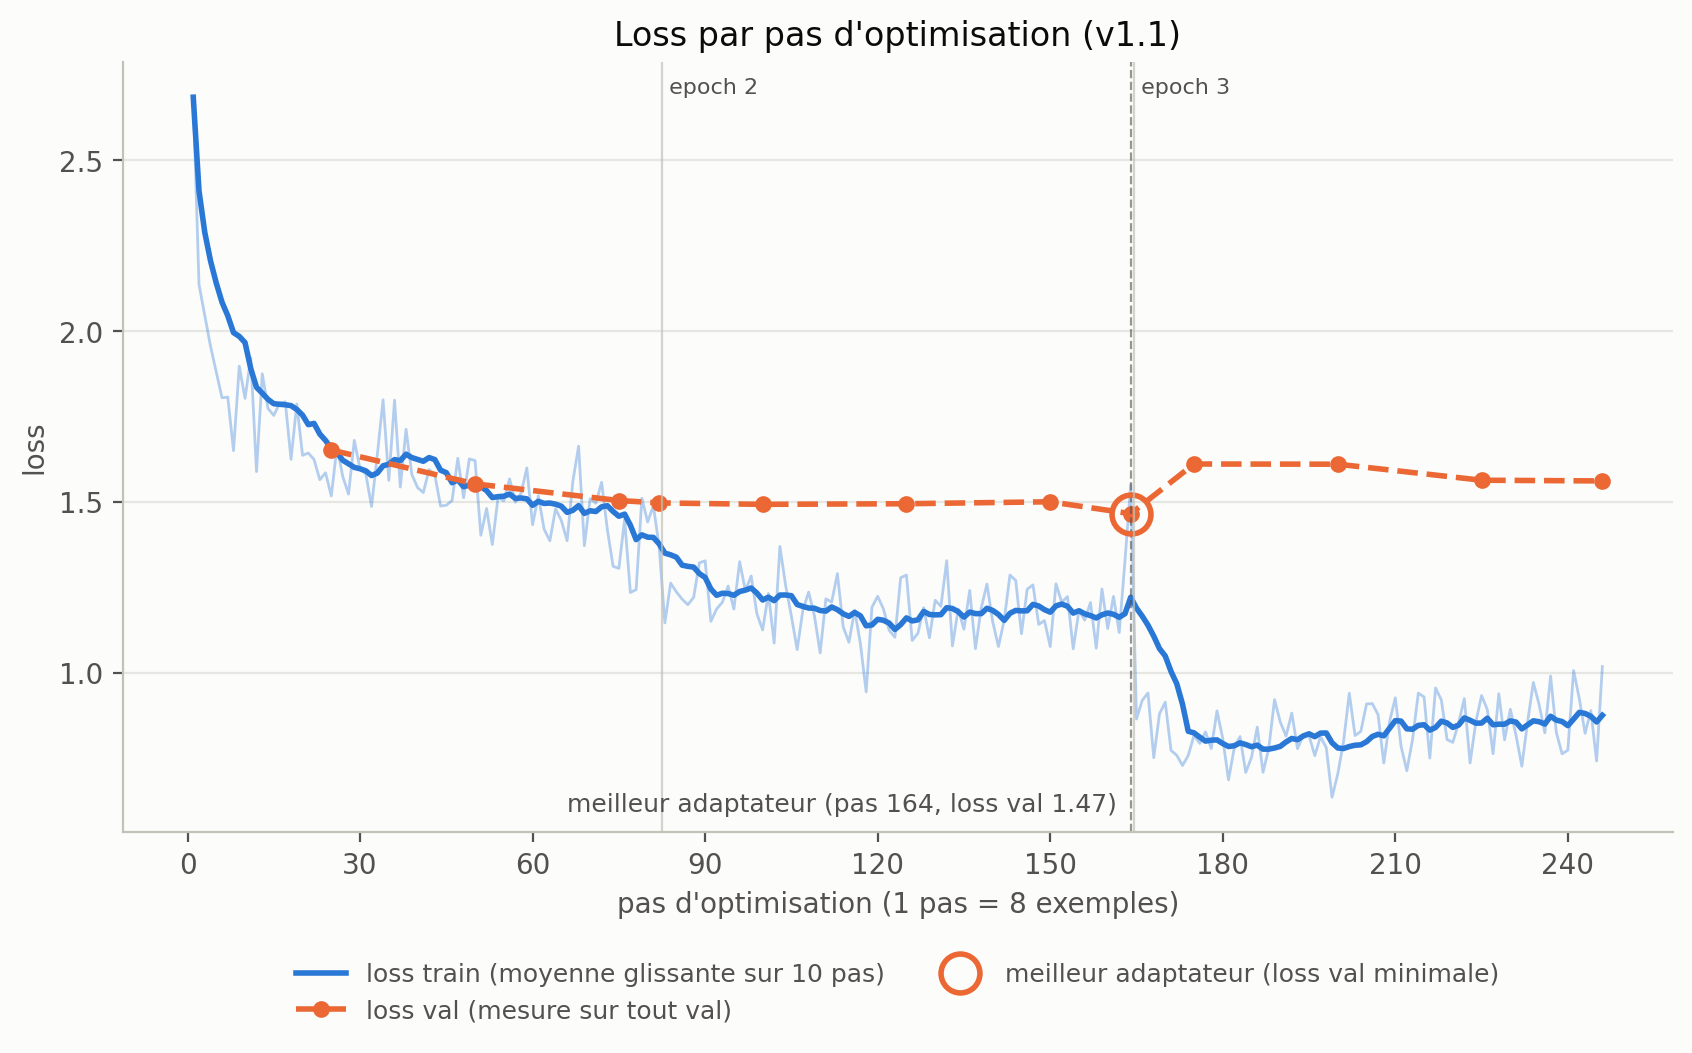

**Lecture.** Un point de la loss val = une mesure sur les 177 exemples de `val`, faite tous les 25 pas (12 mesures au total). La courbe de val commence au pas 25 : c'est la première mesure. La loss train passe de 1.97 (10 premiers pas) à 0.88 (10 derniers). La loss val est minimale (1.466) au pas 164 ; à la dernière mesure elle vaut 1.562, donc elle remonte par rapport au minimum. Arrêt : arrêt anticipé.

Loss train qui baisse et loss val qui remonte : c'est le signe habituel de surapprentissage (le modèle colle à ses exemples). C'est une indication, pas une preuve : un seul run, et un `val` étroit.

**Loss et verdict.** La loss val mesure le texte entier (verdict et feedback), pas seulement le verdict. Une loss val qui remonte n'empêche pas un bon verdict : l'exactitude du §1.4 (85.9%) vient de l'adaptateur du meilleur moment, évalué sur le verdict seul.

In [17]:
from src.training.plot_losses import plot_training_run, read_csv_columns

png = f"{EVAL_DIR}/courbe_{RUN_NAME}.png"
plot_training_run(RUN_DIR, png, f"Loss par pas d'optimisation ({RUN_NAME})")
display(Image(filename=png))

train = read_csv_columns(run / "historique_pas.csv")["loss_train"]
val = read_csv_columns(run / "historique_val.csv")
best_loss, last_loss = min(val["loss_val"]), val["loss_val"][-1]
rises = last_loss > best_loss
train_down = sum(train[-10:]) < sum(train[:10])  # la loss train baisse-t-elle ?
overfit = "Loss train qui baisse et loss val qui remonte : c'est le signe habituel de surapprentissage (le modèle colle à ses exemples). " if rises and train_down else ""
accuracy = json.loads(Path(LORA_JSON).read_text(encoding="utf-8"))["accuracy"]
display(Markdown(f"""**Lecture.** Un point de la loss val = une mesure sur les {config['num_val_examples']} exemples de `val`, faite {rhythm} ({len(val['loss_val'])} mesures au total). La courbe de val commence au pas {val['pas'][0]:.0f} : c'est la première mesure. La loss train passe de {sum(train[:10]) / 10:.2f} (10 premiers pas) à {sum(train[-10:]) / 10:.2f} (10 derniers). La loss val est minimale ({best_loss:.3f}) au pas {result['meilleur_pas']} ; à la dernière mesure elle vaut {last_loss:.3f}, donc elle {'remonte' if rises else 'ne remonte pas'} par rapport au minimum. Arrêt : {result['raison_arret']}.

{overfit}C'est une indication, pas une preuve : un seul run, et un `val` étroit.

**Loss et verdict.** La loss val mesure le texte entier (verdict et feedback), pas seulement le verdict. Une loss val qui remonte n'empêche pas un bon verdict : l'exactitude du §1.4 ({accuracy:.1%}) vient de l'adaptateur du meilleur moment, évalué sur le verdict seul."""))

In [18]:
from src.training.plot_losses import find_best_epoch, read_loss_history
from src.training.train import ACCUMULATION_STEPS, LEARNING_RATE

fmt_lr = lambda value: f"{value:.0e}".replace("e-0", "e-")  # 0.0002 -> 2e-4

def old_row(name, folder, gpu, lr, accumulation):
    """Ligne du tableau pour un essai dont la loss val est mesurée à chaque epoch."""
    path = RESULTS / folder / "historique_loss.csv"
    history = read_loss_history(str(path))
    return [name, gpu, fmt_lr(lr), f"lot de 1 x {accumulation} accumulations, mesure par epoch", f"{min(history['loss_val']):.4f}",
            f"epoch {find_best_epoch(history)}"]

essai2 = json.loads((RESULTS / "train_v0.3" / "config.json").read_text(encoding="utf-8"))
rows = [old_row("essai 1 (v0.2)", "train_v0.2", "RTX 4070", LEARNING_RATE, ACCUMULATION_STEPS),  # v0.2 n'a pas de config.json : valeurs par défaut du code
        old_row("essai 2 (v0.3)", "train_v0.3", essai2["gpu"], essai2["learning_rate"], essai2["accumulation_steps"]),
        [f"run final ({RUN_NAME})", config["gpu"], fmt_lr(config["learning_rate"]), f"vrai lot de {batch}, mesure val {rhythm}",
         f"{result['meilleure_loss_val']:.4f}", f"pas {result['meilleur_pas']} (epoch {result['meilleure_epoch']})"]]
head = ["Essai", "Matériel", "Learning rate", "Protocole", "Loss val minimale", "Meilleur moment"]
table = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)] + ["| " + " | ".join(r) + " |" for r in rows]
display(Markdown("\n".join(table) + "\n\n**Essais successifs, protocoles différents : pas comparables ligne à ligne** (ce n'est pas un même modèle qui progresse). En particulier, le run final est mesuré plus souvent : son minimum est plus facile à trouver."))

| Essai | Matériel | Learning rate | Protocole | Loss val minimale | Meilleur moment |
|---|---|---|---|---|---|
| essai 1 (v0.2) | RTX 4070 | 2e-4 | lot de 1 x 8 accumulations, mesure par epoch | 1.4756 | epoch 1 |
| essai 2 (v0.3) | NVIDIA A100-SXM4-80GB | 1e-4 | lot de 1 x 8 accumulations, mesure par epoch | 1.4701 | epoch 2 |
| run final (v1.1) | NVIDIA A100-SXM4-80GB | 1e-4 | vrai lot de 8, mesure val tous les 25 pas | 1.4659 | pas 164 (epoch 2) |

**Essais successifs, protocoles différents : pas comparables ligne à ligne** (ce n'est pas un même modèle qui progresse). En particulier, le run final est mesuré plus souvent : son minimum est plus facile à trouver.

## 3. Pourquoi ces réglages

Chaque réglage vient d'une contrainte (matériel, taille des données) ou d'une observation. Ceux qui sont seulement usuels, ou qui n'ont pas été testés, sont dits comme tels. Les valeurs sont lues dans `config.json` du run, dans les fichiers des essais précédents ou calculées.

In [19]:
from src.training.dataset import MAX_LENGTH

n_train = config["num_train_examples"]
steps = lambda b: math.ceil(n_train / b)  # pas par epoch pour un lot effectif de b
seconds = {v: read_csv_columns(RESULTS / f"train_{v}" / "historique_loss.csv")["secondes"] for v in ("v0.2", "v0.3")}
per_example = {v: sum(s) / len(s) / n_train for v, s in seconds.items()}  # secondes par exemple, même nombre d'exemples pour les trois runs
by_batch = ", ".join(f"lot {b} : {steps(b)}" for b in (4, 8, 16, 32))
display(Markdown(f"""**Ce que la mémoire impose**

- 4 bits : le modèle occupe {gb_4bit:.1f} Go sur le GPU, contre environ {n_total * 2 / 1024**3:.0f} Go en 16 bits (2 octets par poids). Le 16 bits n'a pas été comparé.
- Matériel : sur la RTX 4070 (12 Go), un exemple prenait environ {per_example['v0.2']:.0f} s, contre environ {per_example['v0.3']:.1f} s sur l'A100 (moyennes des durées d'epoch). La 4070 avait son GPU plein : c'est un constat, pas une cause mesurée. D'où Colab.
- Découpe du lot : {per_step} conversations x {config['accumulation_steps']} accumulation(s) = lot effectif de {batch}, sur {config['gpu']}. Sur un GPU de 60 Go ou moins, la cellule de mise en place choisirait 4 x 2 (même lot effectif de 8, moins de mémoire, plus lent) ; cette découpe n'a pas été relancée ici. Le test `python -m src.training.train --self-test` vérifie, sur un faux modèle sans GPU, que les gradients sont égaux à 1e-6 près pour 6 exemples découpés en 6 x 1, 1 x 6 ou 2 x 3.

**Ce que les données imposent**

- Lot effectif de {batch} : il y a {n_train} exemples d'entraînement. En général, un petit lot donne plus de corrections par epoch mais plus bruitées. Pas par epoch selon le lot effectif : {by_batch}. {batch} n'a pas été comparé aux autres valeurs.
- `max_length` = {MAX_LENGTH} : mesuré. La conversation la plus longue fait {max(lengths)} tokens, on arrondit au-dessus. C'est un garde-fou : une conversation plus longue provoque une erreur, rien n'est coupé. Chaque lot est complété à la longueur de son exemple le plus long, donc une valeur plus grande ne coûte rien tant qu'aucune conversation ne la dépasse."""))

**Ce que la mémoire impose**

- 4 bits : le modèle occupe 4.0 Go sur le GPU, contre environ 6 Go en 16 bits (2 octets par poids). Le 16 bits n'a pas été comparé.
- Matériel : sur la RTX 4070 (12 Go), un exemple prenait environ 24 s, contre environ 2.0 s sur l'A100 (moyennes des durées d'epoch). La 4070 avait son GPU plein : c'est un constat, pas une cause mesurée. D'où Colab.
- Découpe du lot : 8 conversations x 1 accumulation(s) = lot effectif de 8, sur NVIDIA A100-SXM4-80GB. Sur un GPU de 60 Go ou moins, la cellule de mise en place choisirait 4 x 2 (même lot effectif de 8, moins de mémoire, plus lent) ; cette découpe n'a pas été relancée ici. Le test `python -m src.training.train --self-test` vérifie, sur un faux modèle sans GPU, que les gradients sont égaux à 1e-6 près pour 6 exemples découpés en 6 x 1, 1 x 6 ou 2 x 3.

**Ce que les données imposent**

- Lot effectif de 8 : il y a 649 exemples d'entraînement. En général, un petit lot donne plus de corrections par epoch mais plus bruitées. Pas par epoch selon le lot effectif : lot 4 : 163, lot 8 : 82, lot 16 : 41, lot 32 : 21. 8 n'a pas été comparé aux autres valeurs.
- `max_length` = 4096 : mesuré. La conversation la plus longue fait 3638 tokens, on arrondit au-dessus. C'est un garde-fou : une conversation plus longue provoque une erreur, rien n'est coupé. Chaque lot est complété à la longueur de son exemple le plus long, donc une valeur plus grande ne coûte rien tant qu'aucune conversation ne la dépasse.

In [20]:
from src.training.model import LORA_TARGET_MODULES

hist = {v: read_loss_history(str(RESULTS / f"train_{v}" / "historique_loss.csv")) for v in ("v0.2", "v0.3")}
best_epochs = [find_best_epoch(h) for h in hist.values()]
min_losses = [min(h["loss_val"]) for h in hist.values()]
rise = all(h["loss_val"][-1] > min(h["loss_val"]) for h in hist.values())  # la loss val remonte-t-elle après son minimum ?
every = config["eval_every"]
per_epoch = f"environ {steps(batch) / every:.1f} mesures par epoch" if every else "une mesure par epoch"  # eval_every = 0 : fin d'epoch seulement
display(Markdown(f"""**Ce que l'on a observé**

- {config['epochs']} epochs : valeur de départ, non comparée à d'autres. La loss val est minimale à l'epoch {best_epochs[0]} (essai 1) et à l'epoch {best_epochs[1]} (essai 2){', puis elle remonte' if rise else ''}, de quoi voir le minimum. Ni plus ni moins d'epochs n'ont été essayés.
- Mesure de la loss val {rhythm} : {per_epoch}, une courbe assez fine. Chaque mesure coûte du temps de calcul (non chiffré ici).
- Patience {config['patience']} : arrêt après {config['patience']} mesures de suite sans record. Les mesures de fin d'epoch comptent aussi, donc le nombre de pas avant l'arrêt n'est pas fixe. Choix non testé.
- Learning rate : {fmt_lr(LEARNING_RATE)} dans l'essai 1, {fmt_lr(essai2['learning_rate'])} dans l'essai 2, avec des loss val minimales de {min_losses[0]:.3f} et {min_losses[1]:.3f} : pas de différence nette, et un seul essai chacun. Le run final reprend {fmt_lr(config['learning_rate'])}.

**Valeurs usuelles, non comparées ici**

- Rang {config['lora_rank']} et alpha {config['lora_alpha']} (la correction est multipliée par alpha / r = {config['lora_alpha'] / config['lora_rank']:.0f}) : valeurs courantes en LoRA, non testées contre d'autres.
- Dropout {config['lora_dropout']} : valeur courante, non comparée.
- {len(LORA_TARGET_MODULES)} types de couches adaptées : toutes les couches linéaires des blocs, comme dans l'article QLoRA. Non comparé avec moins de couches. Les comparer est une piste d'amélioration."""))

**Ce que l'on a observé**

- 3 epochs : valeur de départ, non comparée à d'autres. La loss val est minimale à l'epoch 1 (essai 1) et à l'epoch 2 (essai 2), puis elle remonte, de quoi voir le minimum. Ni plus ni moins d'epochs n'ont été essayés.
- Mesure de la loss val tous les 25 pas : environ 3.3 mesures par epoch, une courbe assez fine. Chaque mesure coûte du temps de calcul (non chiffré ici).
- Patience 4 : arrêt après 4 mesures de suite sans record. Les mesures de fin d'epoch comptent aussi, donc le nombre de pas avant l'arrêt n'est pas fixe. Choix non testé.
- Learning rate : 2e-4 dans l'essai 1, 1e-4 dans l'essai 2, avec des loss val minimales de 1.476 et 1.470 : pas de différence nette, et un seul essai chacun. Le run final reprend 1e-4.

**Valeurs usuelles, non comparées ici**

- Rang 16 et alpha 32 (la correction est multipliée par alpha / r = 2) : valeurs courantes en LoRA, non testées contre d'autres.
- Dropout 0.05 : valeur courante, non comparée.
- 7 types de couches adaptées : toutes les couches linéaires des blocs, comme dans l'article QLoRA. Non comparé avec moins de couches. Les comparer est une piste d'amélioration.

## 4. Sauvegarder et recharger

L'adaptateur est le dossier `best/` : il ne contient que les petites matrices `A` et `B`. Le modèle de base n'est pas sauvegardé, on le recharge à part en 4 bits, puis on y branche l'adaptateur. La cellule suivante fait ce chemin en entier sur un exemple de `val` : elle recharge, fait écrire une réponse, vérifie son format, puis libère la mémoire.

In [21]:
from src.agents.baseline import parse_pedagogical_response
from src.training.evaluate_verdicts import label_of
from src.training.model import load_model_with_adapter
from src.training.train import generate_answer

model, tokenizer = load_model_with_adapter(f"{RUN_DIR}/best")
conversation = load_split("val")[0]
answer = generate_answer(model, tokenizer, conversation[:-1])  # sans la réponse attendue, sinon le modèle la recopierait
print(answer)
print(f"\nverdict lu : {label_of(answer)} ; verdict attendu : {label_of(conversation[-1]['content'])}")
assert parse_pedagogical_response(answer)["valid_format"], "format de sortie invalide"
print("format valide")
del model
gc.collect()
torch.cuda.empty_cache()
size_mb = sum(f.stat().st_size for f in Path(RUN_DIR, "best").rglob("*") if f.is_file()) / 1024**2
print(f"taille du dossier best/ : {size_mb:.0f} Mo")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

[VERDICT: PARFAIT]
Tu expliques ce qui te gêne. Tu vois que le plan pourrait réussir sans l'homme, et que sa présence transforme l'acte en un dispositif.

verdict lu : PARFAIT ; verdict attendu : PARFAIT
format valide
taille du dossier best/ : 114 Mo


## 5. Limites et pour refaire

- `val` est étroit : très peu de questions, des exemples très corrélés, et il a servi à choisir l'adaptateur retenu. Les chiffres sont optimistes.
- Les étiquettes (verdicts et feedbacks du dataset) ont été générées par deux LLM. Elles n'ont pas été relues ligne à ligne.
- Un seul entraînement par réglage : on ne sépare pas un vrai effet du hasard.
- Les réglages (lot, epochs, fréquence de mesure, patience, rang, alpha, dropout) n'ont pas été comparés entre eux. Un modèle plus gros n'a pas été essayé.
- `test` contient 3 questions (177 exemples) jamais vues à l'entraînement ni pour choisir l'adaptateur : c'est le chiffre à retenir, mais il reste petit.

**Pour refaire** (depuis la racine du dépôt, sur un GPU Nvidia avec PyTorch installé). Avec moins de mémoire (erreur `CUDA out of memory`), remplacer `--batch-size 8 --accumulation-steps 1` par `--batch-size 4 --accumulation-steps 2` : même lot effectif, plus lent.

```
pip install -r requirements-qlora.txt
python -m src.training.run_training --epochs 3 --learning-rate 1e-4 --patience 4 --eval-every 25 --batch-size 8 --accumulation-steps 1 --output-dir adapters/v1.1
python -m src.training.evaluate_verdicts --adapter none --split val --output eval_base.json
python -m src.training.evaluate_verdicts --adapter adapters/v1.1/best --split val --output eval_lora.json
python -m src.training.evaluate_verdicts --adapter none --split test --output eval_test_base.json
python -m src.training.evaluate_verdicts --adapter adapters/v1.1/best --split test --output eval_test_lora.json
python -m src.training.export_examples --adapter adapters/v1.1/best --eval-base eval_base.json --eval-lora eval_lora.json --number 5 --output exemples.json
```

Le code est dans `src/training/` (`dataset.py`, `model.py`, `train.py`, `run_training.py`, `evaluate_verdicts.py`, `export_examples.py`, `plot_losses.py`).